# Flexibilizações de preço e metas semanais

**Pergunta.** Quanto é necessário flexibilizar cada regra operacional para tornar possível o
planejamento de dez dias úteis, e como a margem prevista responde a flexibilizações adicionais?

O estudo recebe artefatos persistidos: entradas do planejamento e curva preditiva. Mantém o preço
anterior observado, o custo do último dia de treino, o imposto e o calendário desses artefatos.
Cada ponto das análises corresponde a um novo problema de maximização da margem com as regras
explicitadas. A execução é independente do estado de outros notebooks e não lê o holdout.

A exposição apresenta primeiro o modelo, as entradas e o significado das mudanças. Depois calcula
os mínimos de viabilidade, as curvas de margem e as combinações. As saídas são planos condicionais
às regras alteradas; o estudo não escolhe automaticamente qual flexibilização o negócio deve aceitar.

O estudo recebe também o artefato de limites comerciais. A variação entre decisões dentro do
horizonte respeita o teto especificado nesse artefato. Esse teto não se aplica à primeira mudança em relação ao
preço anterior: ela permanece uma regra separada, com seus valores explicitados em cada caso.

**Síntese operacional.** O caso original é inviável. As recuperações isoladas exigem primeira mudança de cerca de R$ 44,394/kg, ou piso semanal de cerca de 76,987 kg, mantendo as outras regras. A variação interna isolada não recupera a viabilidade até o teto de R$ 15/kg. Os intervalos certificados e planos correspondentes são calculados na seção 2. São resultados condicionais à previsão central, sem garantia sobre vendas realizadas.

**Guia das figuras.** As Figuras 3.1.1 a 3.1.3 mostram regras isoladas, teto e meta nominal; a Figura 3.1.4 mostra combinações; a Figura 3.1.5 mostra recuperações mínimas; as Figuras 3.1.6 e 3.1.7 mostram margens e planos das alternativas.

## 1. Modelo, regras e premissas

O objetivo é a soma, nos dez dias, da receita prevista líquida de imposto menos o custo dos quilos
previstos. O preço é a decisão; o volume fica ligado ao preço pela curva publicada, incluindo
calendário e smearing. A igualdade com a curva é mantida em todas as análises.

$$\max \sum_t [(1-\tau)p_t-c]q_t,\qquad
q_t=SF\exp(\beta_0+\gamma_{c(t)})p_t^\beta.$$

As regras de referência são os limites semanais, o suporte de preço por contexto, a mudança entre
decisões consecutivas e a ligação entre o preço anterior e a primeira decisão. Sexta e segunda são
consecutivas para a regra de preço. O limite da primeira mudança é independente do limite interno.

| Parâmetro alterado | Significado | Regras preservadas na análise isolada |
|---|---|---|
| Variação interna | Aumentar o máximo de mudança entre os dias do horizonte | Primeira mudança e faixa semanal |
| Transição inicial | Aumentar a primeira mudança permitida, conservando o preço anterior real | Variação interna e faixa semanal |
| Tolerância inferior | Reduzir o piso semanal, mantendo o teto | Ambas as regras de preço |
| Tolerância superior | Aumentar o teto semanal, mantendo o piso | Ambas as regras de preço |
| Meta nominal | Deslocar piso e teto pela mesma meta | Tolerâncias e ambas as regras de preço |

Aumentar uma folga amplia o conjunto de planos admissíveis. A margem ótima não pode diminuir
nessa operação; diferenças dentro do gap numérico não indicam uma perda econômica demonstrada.
Alterar a meta nominal desloca a faixa e **não** gera conjuntos necessariamente aninhados.

**Premissas.** Um produto, preços contínuos, curva fixa e observacional, previsão pontual e demanda
prevista integralmente atendida. Custo unitário e imposto permanecem constantes. Não há estoque,
capacidade, efeitos entre produtos ou transferência de demanda entre dias. O suporte observado
permanece obrigatório neste estudo. O volume previsto não é uma garantia de venda realizada.

In [1]:
# Numeração local de tabelas e figuras desta etapa.
from IPython.display import Markdown, display
_num_tabela = 0
_num_figura = 0

def exibir_tabela(objeto, titulo):
    global _num_tabela
    _num_tabela += 1
    display(Markdown(f"**Tabela 3.1.{_num_tabela}.** {titulo}. Unidades indicadas nas colunas; fonte: cálculo deste notebook."))
    display(objeto)

def legendar_figura(titulo):
    global _num_figura
    _num_figura += 1
    display(Markdown(f"**Figura 3.1.{_num_figura}.** {titulo}. Fonte: cálculo deste notebook; eixos indicam as unidades."))


from pathlib import Path
from itertools import product
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.modeling.demand_curve import file_sha256, load_artifact
from src.optimization.planning_inputs import load_planning_inputs, load_relaxation_limits
from src.optimization.relaxation_study import (
    Relaxation, RelaxationStudy, compare_margin_relaxations, pareto_feasible, summarize,
)

INPUT_PATH = ROOT / 'models/otimizacao/entradas_planejamento.json'
LIMITS_PATH = ROOT / 'models/otimizacao/limites_flexibilizacoes.json'
TABLES = ROOT / 'reports/tables/relaxacoes'
FIGURES = ROOT / 'reports/figures/relaxacoes'
RESULT_PATH = ROOT / 'data/processed/minerva_simulacao_relaxacoes.json'
PLAN_PATH = ROOT / 'data/processed/minerva_planos_relaxacoes.csv'
for folder in [TABLES, FIGURES, RESULT_PATH.parent]:
    folder.mkdir(parents=True, exist_ok=True)

problem, planning_inputs = load_planning_inputs(INPUT_PATH, root=ROOT)
MODEL_PATH = ROOT / planning_inputs['model_file']
input_hash = file_sha256(INPUT_PATH)
model_hash = file_sha256(MODEL_PATH)
relaxation_limits = load_relaxation_limits(LIMITS_PATH)
limits_file_hash = file_sha256(LIMITS_PATH)
MAX_INTERNAL = relaxation_limits['daily_variation_ceiling']
study = RelaxationStudy(
    problem, time_limit=30, mip_gap=1e-6,
    daily_variation_ceiling=MAX_INTERNAL,
    initial_transition_ceiling=relaxation_limits['initial_transition_ceiling'],
)
BASE = study.evaluate()
nominal_target = next(iter(problem.targets.values()))
assert len(set(problem.targets.values())) == 1, 'O painel usa uma meta nominal comum às semanas.'
STATUS = {
    'optimal': 'Ótimo certificado', 'infeasible': 'Inviável provado',
    'feasible_time_limit': 'Plano verificado; limite de tempo',
    'feasible_suboptimal': 'Plano verificado; sem certificado',
    'feasible_unproven': 'Plano verificado; sem certificado',
    'no_solution': 'Sem solução encontrada', 'error': 'Erro de execução',
    'validation_failed': 'Falha de verificação',
}
LABELS = {
    'daily_variation': 'Variação interna', 'initial_transition': 'Transição inicial',
    'tolerance_lower': 'Tolerância inferior', 'tolerance_upper': 'Tolerância superior',
}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_columns', 20)

def numero(valor, casas=2):
    return f'{valor:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def publicar(texto):
    display(Markdown(texto))

def avaliar_regra(regra, valores, **conditions):
    return [dict(regra=regra, valor=float(value), **summarize(
        study.evaluate(study.relaxation_at(regra, float(value)), **conditions)))
        for value in sorted(set(valores))]

inputs = pd.DataFrame([
    ('Entradas recebidas', str(INPUT_PATH.relative_to(ROOT))),
    ('Limites comerciais recebidos', str(LIMITS_PATH.relative_to(ROOT))),
    ('Teto do estudo para variação interna (R$/kg)', MAX_INTERNAL),
    ('Curva recebida', planning_inputs['model_file']),
    ('Corte das entradas', planning_inputs['decision_cutoff']),
    ('Preço anterior observado (R$/kg)', problem.initial_price),
    ('Custo do último dia de treino (R$/kg)', problem.costs[0]),
    ('Imposto sobre receita', problem.tax_rate),
    ('Meta nominal por semana (kg)', nominal_target),
    ('Tolerância inferior', problem.tol_lower),
    ('Tolerância superior', problem.tol_upper),
    ('Variação interna (R$/kg)', problem.daily_variation),
    ('Primeira mudança (R$/kg)', problem.init_var),
    ('Smearing', problem.artifact['smearing_factor']),
], columns=['Entrada', 'Valor'])
exibir_tabela(inputs, 'Entradas e fontes do planejamento')
exibir_tabela(pd.DataFrame.from_dict(BASE['diagnostics']['weeks'], orient='index')[[
    'lower_kg', 'upper_kg', 'minimum_reachable_kg', 'maximum_reachable_kg', 'shortage_kg'
]].round(3), 'Envelope de volumes sob as regras originais (kg)')
publicar(f"**Interpretação das entradas.** O caso de referência é **{STATUS[BASE['status']].lower()}**. "
         f"O preço anterior é R$ {numero(problem.initial_price)}/kg, o custo unitário constante é "
         f"R$ {numero(problem.costs[0], 6)}/kg e o smearing recebido é "
         f"{numero(problem.artifact['smearing_factor'], 7)}. A curva e as fontes são conferidas "
         "contra os hashes do artefato de entradas antes de resolver qualquer flexibilização.")



2026-11-08 19:04:06.201 | INFO     | src.config:<module>:11 - PROJ_ROOT path is: /Users/ngodeny/Documents/mestrado/202602-resolucao_problemas


**Tabela 3.1.1.** Entradas e fontes do planejamento. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Entrada,Valor
0,Entradas recebidas,models/otimizacao/entradas_planejamento.json
1,Limites comerciais recebidos,models/otimizacao/limites_flexibilizacoes.json
2,Teto do estudo para variação interna (R$/kg),15.0
3,Curva recebida,models/preditivo_diario/curva_demanda.json
4,Corte das entradas,2025-10-31
5,Preço anterior observado (R$/kg),1318.919594
6,Custo do último dia de treino (R$/kg),1010.446838
7,Imposto sobre receita,0.07
8,Meta nominal por semana (kg),165.0
9,Tolerância inferior,0.3


**Tabela 3.1.2.** Envelope de volumes sob as regras originais (kg). Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,lower_kg,upper_kg,minimum_reachable_kg,maximum_reachable_kg,shortage_kg
semana_1,115.5,214.5,69.694,76.987,38.513
semana_2,115.5,214.5,63.503,84.616,30.884


**Interpretação das entradas.** O caso de referência é **inviável provado**. O preço anterior é R$ 1.318,92/kg, o custo unitário constante é R$ 1.010,446838/kg e o smearing recebido é 1,0912057. A curva e as fontes são conferidas contra os hashes do artefato de entradas antes de resolver qualquer flexibilização.

## 2. Como são encontrados os mínimos de viabilidade

**Pergunta.** Qual é a menor ampliação de uma regra que permite um plano válido, mantendo as demais?

**Método.** Para limites de mudança e tolerâncias, a busca por bisseção conserva um valor inviável
provado e outro com plano verificado. Um envelope de volume que não alcança a faixa semanal
certifica inviabilidade; a interseção com a faixa, por si só, não comprova a existência de um plano.
A factibilidade é confirmada pelo solver e pela recomposição das restrições.

A precisão é R$ 0,001/kg para mudanças de preço e 0,000001 para frações de tolerância.
O mínimo é apresentado pelo lado factível do intervalo. A margem desse ponto é maximizada com
Gurobi, usando o mesmo objetivo e gap da análise de referência. Terminar sem encontrar solução
não é convertido em inviabilidade.

Para o teto semanal, testa-se se ampliá-lo pode recuperar o caso. Uma alteração que não resolve a
causa da inviabilidade é reportada como sem recuperação na faixa examinada, sem atribuir margem.
Não se busca mínimo por bisseção para a meta nominal, pois essa mudança desloca os dois limites.

A busca da variação interna termina no teto comercial recebido. Se a recuperação exigir mais
que esse teto, o estudo registra ausência de recuperação isolada dentro do intervalo permitido
e examina combinações de outras regras. Esse caso não participa da referência financeira.

Os certificados das resoluções não lineares seguem o método global documentado pelo Gurobi (versão 13.0); a referência bibliográfica está ao final.

In [2]:
limits = {
    'daily_variation': (MAX_INTERNAL, 1e-3),
    'initial_transition': (120.0, 1e-3),
    'tolerance_lower': (.95, 1e-6),
    'tolerance_upper': (.95, 1e-6),
}
thresholds = [study.minimum(rule, upper=upper, precision=precision)
              for rule, (upper, precision) in limits.items()]
threshold_table = pd.DataFrame(thresholds)
threshold_table['regra'] = threshold_table['rule'].map(LABELS)
threshold_table['piso_resultante_kg'] = np.where(
    threshold_table['rule'] == 'tolerance_lower',
    nominal_target * (1-threshold_table['minimum']), np.nan)
threshold_table.to_csv(TABLES / 'limiares_viabilidade.csv', index=False)
exibir_tabela(threshold_table[['regra', 'status', 'infeasible_value', 'feasible_value',
                         'precision', 'piso_resultante_kg', 'margem_prevista_rs']].round(8), 'Intervalos dos mínimos de viabilidade')
minimum = {row['rule']: row['minimum'] for row in thresholds}
assert all(minimum[rule] is not None for rule in ['initial_transition', 'tolerance_lower'])
if minimum['daily_variation'] is None:
    publicar(f"**Variação interna isolada.** Não recupera a viabilidade até "
             f"**R$ {numero(MAX_INTERNAL)}/kg**, mantendo a primeira mudança em "
             f"R$ {numero(problem.init_var)}/kg e as faixas semanais originais. "
             "Essa alternativa não recebe plano nem margem de comparação.")
else:
    publicar(f"**Variação interna isolada.** O mínimo admissível encontrado é "
             f"R$ {numero(minimum['daily_variation'], 3)}/kg.")
publicar(
    f"**Outras recuperações isoladas.** Mantendo a variação interna em "
    f"R$ {numero(problem.daily_variation)}/kg, a primeira mudança precisa admitir aproximadamente "
    f"**R$ {numero(minimum['initial_transition'], 3)}/kg**. Esse valor não é uma mudança entre "
    "dias do horizonte; é a entrada a partir do preço anterior observado.\n\n"
    f"Alterar somente o piso exige tolerância inferior de aproximadamente "
    f"**{numero(100*minimum['tolerance_lower'], 4)}%**, equivalente a um piso comum de "
    f"**{numero(nominal_target*(1-minimum['tolerance_lower']))} kg**. O teto permanece "
    f"{numero(nominal_target*(1+problem.tol_upper), 1)} kg. Aumentar somente o teto não "
    "recupera o caso: o piso exigido supera o máximo de volume alcançável com as regras de preço."
)

**Tabela 3.1.3.** Intervalos dos mínimos de viabilidade. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,regra,status,infeasible_value,feasible_value,precision,piso_resultante_kg,margem_prevista_rs
0,Variação interna,no_recovery_in_range,15.000000,NaN,0.001000,NaN,NaN
1,Transição inicial,bracketed,44.392746,44.393646,0.001000,NaN,40520.378388
2,Tolerância inferior,bracketed,0.533413,0.533413,0.000001,76.986795,33336.935447
3,Tolerância superior,no_recovery_in_range,0.950000,NaN,0.000001,NaN,NaN


**Variação interna isolada.** Não recupera a viabilidade até **R$ 15,00/kg**, mantendo a primeira mudança em R$ 2,00/kg e as faixas semanais originais. Essa alternativa não recebe plano nem margem de comparação.

**Outras recuperações isoladas.** Mantendo a variação interna em R$ 2,00/kg, a primeira mudança precisa admitir aproximadamente **R$ 44,394/kg**. Esse valor não é uma mudança entre dias do horizonte; é a entrada a partir do preço anterior observado.

Alterar somente o piso exige tolerância inferior de aproximadamente **53,3413%**, equivalente a um piso comum de **76,99 kg**. O teto permanece 214,5 kg. Aumentar somente o teto não recupera o caso: o piso exigido supera o máximo de volume alcançável com as regras de preço.

## 3. Curvas graduais de preço e piso semanal

**Pergunta.** Depois de recuperar a viabilidade, quanto de margem prevista cada folga adicional permite?

**Método.** Cada curva altera somente uma regra. O eixo de piso mostra kg admitidos; reduzir esse
piso aumenta a tolerância inferior. Pontos inviáveis permanecem nas tabelas e aparecem por marcas
vermelhas na base dos painéis. A linha tracejada indica o mínimo calculado quando houver recuperação admissível, e as margens usam a
mesma escala vertical. Os planos permanecem dentro do suporte observado.

Os valores das grades são escolhas de resolução da análise. Os mínimos vêm da busca própria, e
não da primeira posição factível da grade. Margens são previstas e condicionais à curva recebida.

A curva de variação interna fica integralmente dentro do teto comercial recebido.

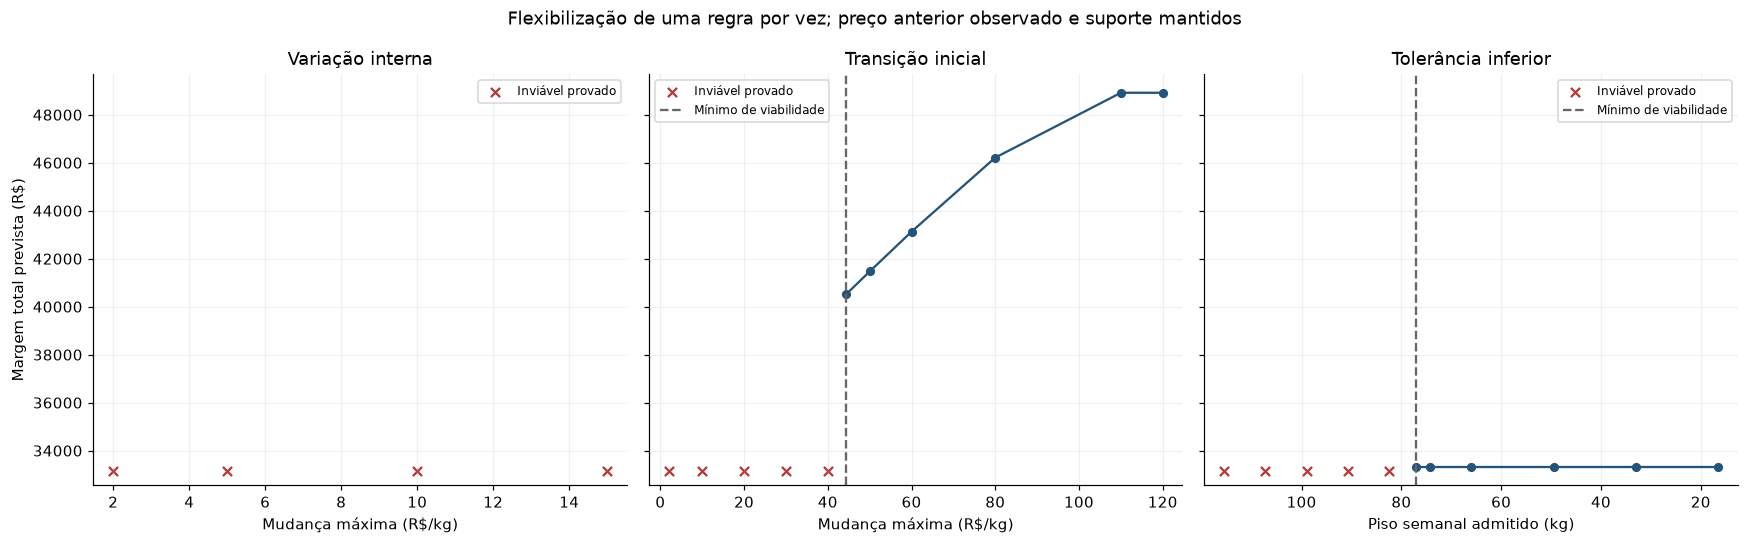

**Figura 3.1.1.** Flexibilização isolada de regras com previsão central e suporte mantido; mesmas escalas financeiras. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Variação interna.** Não há plano verificado na faixa permitida dessa análise isolada.

**Transição inicial.** Nas posições factíveis da grade, a margem prevista fica entre R$ 40.520,38 e R$ 48.917,58.

**Tolerância inferior.** Nas posições factíveis da grade, a margem prevista fica entre R$ 33.336,94 e R$ 33.336,94.

Reduzir apenas o piso permite aceitar volumes menores, preservando a trajetória de preços alcançável. Isso recupera a viabilidade sem criar a mesma liberdade comercial de ampliar as mudanças de preço. Um patamar de margem indica que ampliar aquela folga já não altera a melhor decisão sob as outras regras mantidas.

In [3]:
grids = {
    'daily_variation': [problem.daily_variation, 5, 10, MAX_INTERNAL, minimum['daily_variation']],
    'initial_transition': [2, 10, 20, 30, 40, 50, 60, 80, 110, 120, minimum['initial_transition']],
    'tolerance_lower': [.30, .35, .40, .45, .50, .55, .60, .70, .80, .90, minimum['tolerance_lower']],
}
grids = {rule: [value for value in values if value is not None]
         for rule, values in grids.items()}
grids['daily_variation'] = [value for value in grids['daily_variation'] if value <= MAX_INTERNAL]
curve_rows = []
for rule, values in grids.items():
    curve_rows.extend(avaliar_regra(rule, values))
curves = pd.DataFrame(curve_rows)
curves.to_csv(TABLES / 'curvas.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, rule in zip(axes, grids):
    panel = curves.loc[curves['regra'] == rule].sort_values('valor')
    x = panel['valor'].to_numpy()
    boundary = minimum[rule]
    if rule == 'tolerance_lower':
        x = nominal_target * (1-x)
        boundary = nominal_target*(1-boundary) if boundary is not None else None
    padding = max(float(np.ptp(x)) * .04, .1)
    ax.set_xlim(x.min() - padding, x.max() + padding)
    if rule == 'tolerance_lower':
        ax.invert_xaxis()
    ax.plot(x, panel['margem_prevista_rs'], 'o-', color='#24547a', ms=5)
    failed = panel['status'].eq('infeasible').to_numpy()
    ax.scatter(x[failed], np.full(failed.sum(), .035), transform=ax.get_xaxis_transform(),
               color='#b23b3b', marker='x', label='Inviável provado')
    if boundary is not None:
        ax.axvline(boundary, color='0.4', ls='--', label='Mínimo de viabilidade')
    ax.set_title(LABELS[rule])
    ax.set_xlabel('Piso semanal admitido (kg)' if rule == 'tolerance_lower' else 'Mudança máxima (R$/kg)')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Margem total prevista (R$)')
fig.suptitle('Flexibilização de uma regra por vez; preço anterior observado e suporte mantidos')
fig.tight_layout()
fig.savefig(FIGURES / 'curvas.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Flexibilização isolada de regras com previsão central e suporte mantido; mesmas escalas financeiras')
for rule in grids:
    valid = curves.loc[(curves['regra'] == rule) & curves['plano_verificado']]
    if valid.empty:
        publicar(f"**{LABELS[rule]}.** Não há plano verificado na faixa permitida dessa análise isolada.")
    else:
        publicar(f"**{LABELS[rule]}.** Nas posições factíveis da grade, a margem prevista fica entre "
                 f"R$ {numero(valid['margem_prevista_rs'].min())} e "
                 f"R$ {numero(valid['margem_prevista_rs'].max())}.")
publicar('Reduzir apenas o piso permite aceitar volumes menores, preservando a trajetória de preços '
         'alcançável. Isso recupera a viabilidade sem criar a mesma liberdade comercial de ampliar '
         'as mudanças de preço. Um patamar de margem indica que ampliar aquela folga já não altera '
         'a melhor decisão sob as outras regras mantidas.')

## 4. Efeito do teto semanal após recuperar a viabilidade

**Pergunta.** O teto deixa de importar porque sua flexibilização isolada não recupera o caso?

**Método.** A tolerância superior é variada em duas condições explícitas: regras de preço de
referência; e primeira ligação removida, mantendo a variação interna. A segunda condição permite
examinar o efeito do teto em um problema factível. A tolerância inferior e a meta nominal não mudam.

Essa comparação separa recuperar a viabilidade de ampliar a margem. As duas condições não devem
ser apresentadas como se fossem o mesmo conjunto de regras.

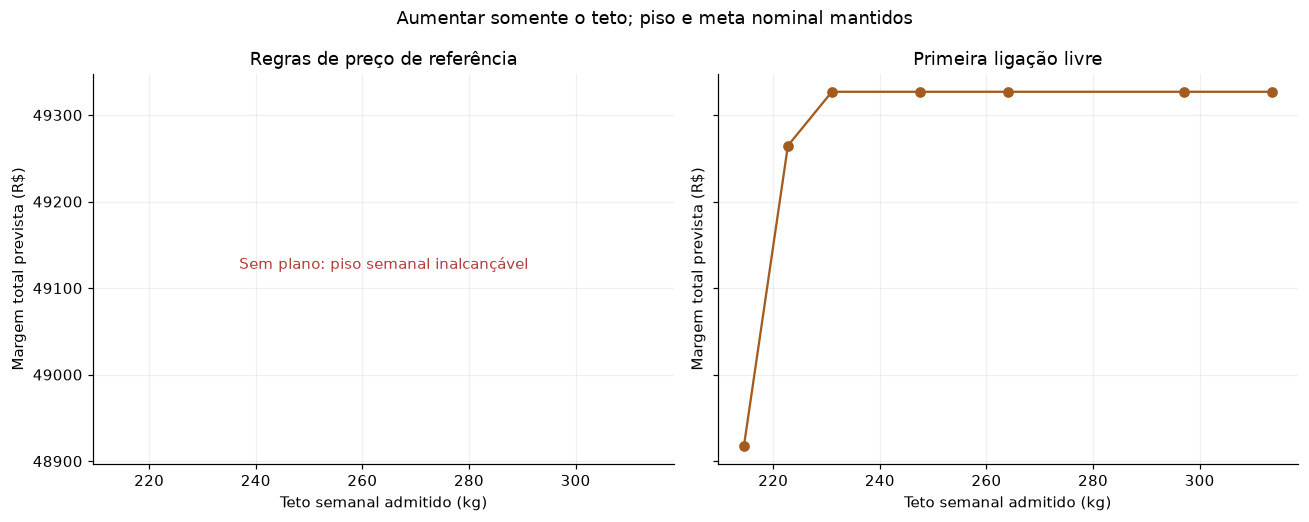

**Figura 3.1.2.** Teto semanal variado com regras originais e com primeira ligação removida, em condições separadas. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Interpretação.** A ampliação do teto não resolve o déficit do caso de referência. Com a primeira ligação livre, o teto pode limitar o volume que maximiza a margem. Nessa condição, a grade apresenta margens entre R$ 48.917,58 e R$ 49.326,90. Essas diferenças são simuladas sob uma exceção operacional declarada.

In [4]:
upper_rows = []
for free_initial in [False, True]:
    condition = 'Primeira ligação livre' if free_initial else 'Regras de preço de referência'
    for row in avaliar_regra('tolerance_upper', [.30, .35, .40, .50, .60, .80, .90],
                             enforce_initial=not free_initial):
        upper_rows.append(dict(condicao=condition, **row))
upper_curves = pd.DataFrame(upper_rows)
upper_curves.to_csv(TABLES / 'curva_teto.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, (condition, panel) in zip(axes, upper_curves.groupby('condicao', sort=False)):
    x = nominal_target * (1 + panel['valor'])
    ax.plot(x, panel['margem_prevista_rs'], 'o-', color='#a35b20')
    if not panel['plano_verificado'].any():
        ax.text(.5, .5, 'Sem plano: piso semanal inalcançável', transform=ax.transAxes,
                ha='center', wrap=True, color='#b23b3b')
    ax.set(title=condition, xlabel='Teto semanal admitido (kg)', ylabel='Margem total prevista (R$)')
    ax.grid(alpha=.2)
fig.suptitle('Aumentar somente o teto; piso e meta nominal mantidos')
fig.tight_layout()
fig.savefig(FIGURES / 'curva_teto.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Teto semanal variado com regras originais e com primeira ligação removida, em condições separadas')
conditional = upper_curves.loc[upper_curves['plano_verificado']]
publicar(f"**Interpretação.** A ampliação do teto não resolve o déficit do caso de referência. "
         "Com a primeira ligação livre, o teto pode limitar o volume que maximiza a margem. "
         f"Nessa condição, a grade apresenta margens entre R$ "
         f"{numero(conditional['margem_prevista_rs'].min())} e R$ "
         f"{numero(conditional['margem_prevista_rs'].max())}. Essas diferenças são simuladas "
         "sob uma exceção operacional declarada.")

## 5. Sensibilidade da meta nominal

**Pergunta.** O que muda quando a própria meta semanal é reduzida ou aumentada?

**Método.** A meta comum às duas semanas é variada, conservando as tolerâncias, o preço anterior,
as duas regras de mudança e o suporte. Reduzir a meta abaixa simultaneamente o piso e o teto.
Por isso, uma meta muito baixa também pode ser inviável: a trajetória de preço pode não permitir
reduzir o volume até o teto. Não se interpreta essa curva como uma flexibilização monotônica.

**Tabela 3.1.4.** Sensibilidade da meta nominal e faixas semanais. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,meta_kg,status,margem_prevista_rs,semana_1_piso_kg,semana_1_teto_kg
0,40.0,infeasible,NaN,28.0,52.0
1,50.0,infeasible,NaN,35.0,65.0
2,60.0,optimal,32627.890,42.0,78.0
3,70.0,optimal,33336.935,49.0,91.0
4,80.0,optimal,33336.935,56.0,104.0
5,90.0,optimal,33336.935,63.0,117.0
6,100.0,optimal,33336.935,70.0,130.0
7,110.0,infeasible,NaN,77.0,143.0
8,125.0,infeasible,NaN,87.5,162.5
9,140.0,infeasible,NaN,98.0,182.0


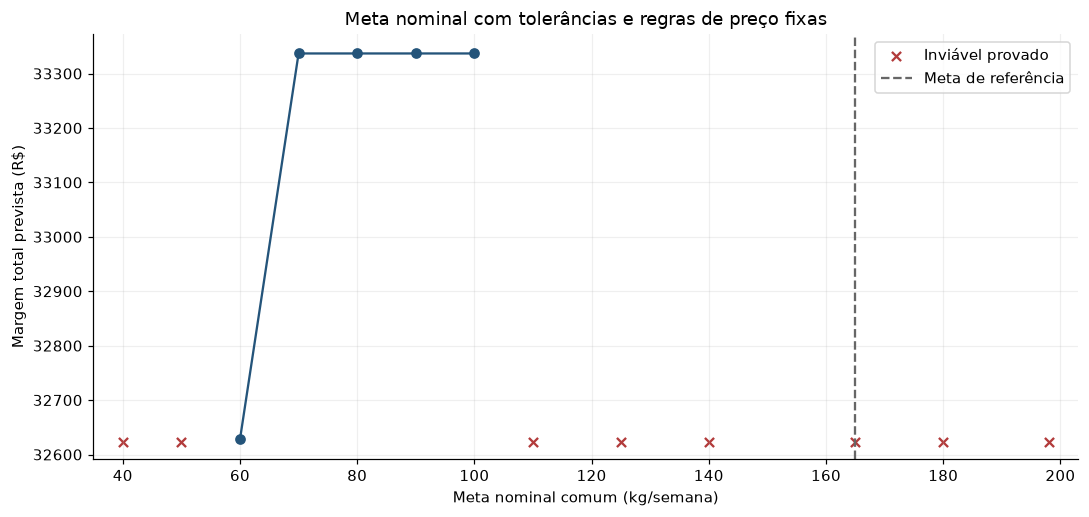

**Figura 3.1.3.** Deslocamento conjunto de piso e teto; a sensibilidade da meta não é uma relaxação monotônica. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Interpretação.** Na grade examinada, há planos válidos para metas de 60 a 100 kg. Esses são pontos amostrados, não os limites exatos de um intervalo contínuo. As margens devem ser lidas com a faixa de volume correspondente a cada meta.

In [5]:
target_rows = []
for target in [40, 50, 60, 70, 80, 90, 100, 110, 125, 140, 165, 180, 198]:
    row = summarize(study.evaluate(Relaxation(target_nominal_factor=target / nominal_target)))
    target_rows.append(dict(meta_kg=float(target), **row))
target_curve = pd.DataFrame(target_rows)
target_curve.to_csv(TABLES / 'sensibilidade_meta_nominal.csv', index=False)
exibir_tabela(target_curve[['meta_kg', 'status', 'margem_prevista_rs',
                      'semana_1_piso_kg', 'semana_1_teto_kg']].round(3), 'Sensibilidade da meta nominal e faixas semanais')
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(target_curve['meta_kg'], target_curve['margem_prevista_rs'], 'o-', color='#24547a')
failed = target_curve['status'].eq('infeasible')
ax.scatter(target_curve.loc[failed, 'meta_kg'], np.full(failed.sum(), .04), marker='x',
           color='#b23b3b', transform=ax.get_xaxis_transform(), label='Inviável provado')
ax.set_xlim(target_curve['meta_kg'].min() - 5, target_curve['meta_kg'].max() + 5)
ax.axvline(nominal_target, color='0.4', ls='--', label='Meta de referência')
ax.set(title='Meta nominal com tolerâncias e regras de preço fixas',
       xlabel='Meta nominal comum (kg/semana)', ylabel='Margem total prevista (R$)')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'meta_nominal.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Deslocamento conjunto de piso e teto; a sensibilidade da meta não é uma relaxação monotônica')
valid_targets = target_curve.loc[target_curve['plano_verificado'], 'meta_kg']
publicar(f"**Interpretação.** Na grade examinada, há planos válidos para metas de "
         f"{numero(valid_targets.min(), 0)} a {numero(valid_targets.max(), 0)} kg. "
         "Esses são pontos amostrados, não os limites exatos de um intervalo contínuo. "
         "As margens devem ser lidas com a faixa de volume correspondente a cada meta.")

## 6. Combinações de flexibilizações e fronteiras na grade

**Pergunta.** Pequenas alterações simultâneas podem recuperar a viabilidade sem uma grande alteração isolada?

**Método.** Três grades cruzam transição inicial e variação interna; variação interna e redução do
piso; transição inicial e redução do piso. A terceira regra e o teto permanecem na referência.
Cada célula registra status, limites declarados, margem, volumes e folgas.

As cores representam margem de planos verificados. Células cinzas são inviáveis provadas. A
fronteira marca combinações factíveis para as quais nenhuma outra posição da mesma grade exige
alterações menores nas duas regras. Cada eixo permanece na sua unidade. A margem é reportada,
mas não entra em uma soma arbitrária com R$ de mudança ou kg de meta.

A fronteira é aproximada pela grade: ela não comprova o mínimo contínuo de cada combinação.

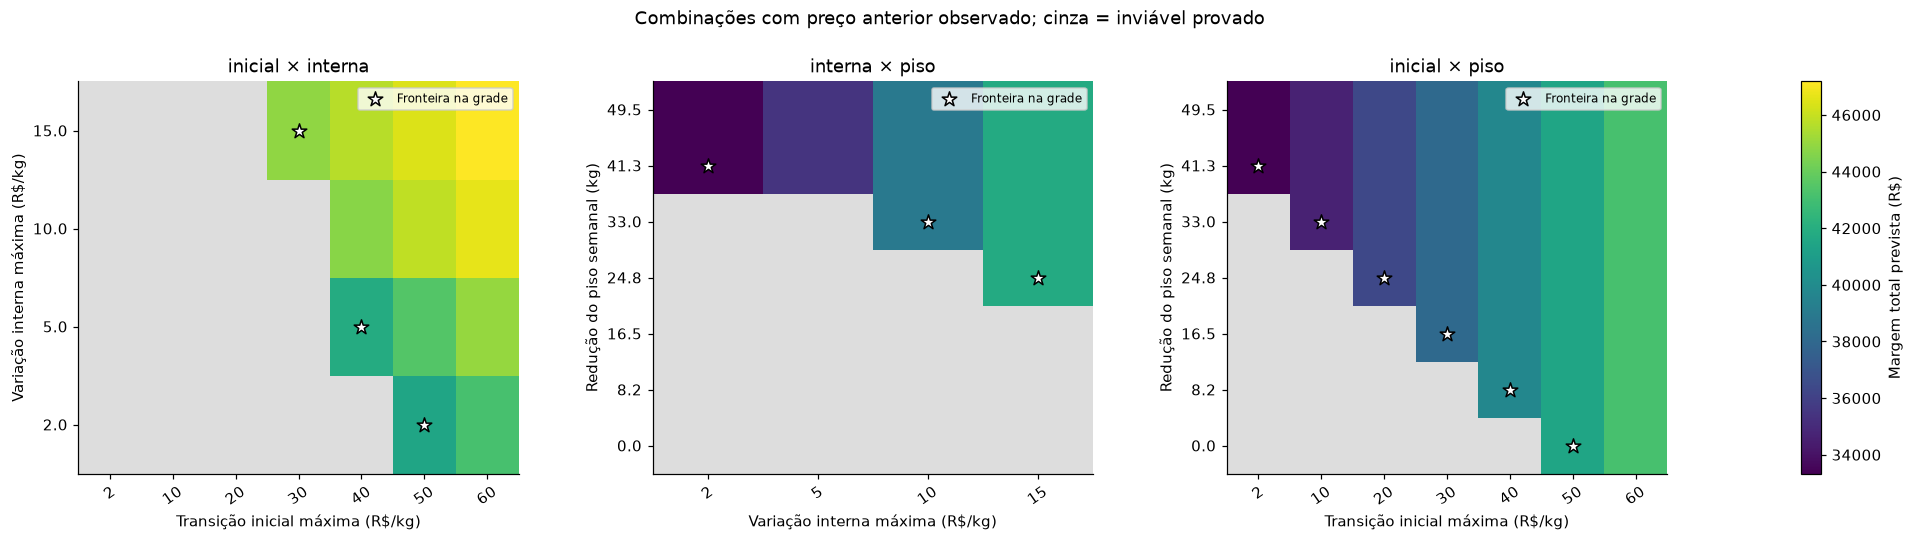

**Figura 3.1.4.** Grades de duas flexibilizações; a fronteira operacional é aproximada pelos pontos da grade. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Tabela 3.1.5.** Combinações não dominadas nas grades operacionais. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,par,x,y,margem_prevista_rs,case_id
0,inicial_interna,30.0,15.00,44865.390,c0094
1,inicial_interna,40.0,5.00,41845.012,c0095
2,inicial_interna,50.0,2.00,41468.431,c0048
3,interna_piso,2.0,41.25,33336.935,c0056
4,interna_piso,10.0,33.00,38922.710,c0113
5,interna_piso,15.0,24.75,41802.318,c0118
6,inicial_piso,2.0,41.25,33336.935,c0056
7,inicial_piso,10.0,33.00,34666.207,c0125
8,inicial_piso,20.0,24.75,36354.384,c0130
9,inicial_piso,30.0,16.50,38061.208,c0135


**Interpretação.** Foram avaliadas 105 posições nas três grades. 57 possuem plano verificado e 12 posições pertencem às fronteiras operacionais amostradas. As combinações permitem comparar alternativas com unidades distintas sem escolher pesos comerciais arbitrários. O maior valor financeiro não determina sozinho qual mudança de regra é aceitável.

In [6]:
combinations = []
for pair, xs, ys in [
    ('inicial_interna', [2, 10, 20, 30, 40, 50, 60], [2, 5, 10, 15, 20, 25, 30]),
    ('interna_piso', [2, 5, 10, 15, 20, 25, 30], [.30, .35, .40, .45, .50, .55, .60]),
    ('inicial_piso', [2, 10, 20, 30, 40, 50, 60], [.30, .35, .40, .45, .50, .55, .60]),
]:
    if pair == 'inicial_interna':
        ys = [value for value in ys if value <= MAX_INTERNAL]
    elif pair == 'interna_piso':
        xs = [value for value in xs if value <= MAX_INTERNAL]
    for x, y in product(xs, ys):
        if pair == 'inicial_interna':
            relaxation = Relaxation(initial_transition_factor=x/problem.init_var,
                                    daily_variation_factor=y/problem.daily_variation)
        elif pair == 'interna_piso':
            relaxation = Relaxation(daily_variation_factor=x/problem.daily_variation,
                                    tolerance_lower_factor=y/problem.tol_lower)
        else:
            relaxation = Relaxation(initial_transition_factor=x/problem.init_var,
                                    tolerance_lower_factor=y/problem.tol_lower)
        row = summarize(study.evaluate(relaxation))
        cost_y = y if pair == 'inicial_interna' else nominal_target * (y-problem.tol_lower)
        combinations.append(dict(par=pair, x=float(x), y=float(cost_y), **row))
combination_table = pd.DataFrame(combinations)
frontiers = pd.concat([
    pareto_feasible(panel, ['x', 'y']) for _, panel in combination_table.groupby('par', sort=False)
], ignore_index=True)
combination_table.to_csv(TABLES / 'combinacoes.csv', index=False)
frontiers.to_csv(TABLES / 'fronteiras.csv', index=False)
fig = plt.figure(figsize=(18, 5.4))
layout = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, .045], wspace=.40)
axes = [fig.add_subplot(layout[0, i]) for i in range(3)]
color_axis = fig.add_subplot(layout[0, 3])
maximum_margin = combination_table['margem_prevista_rs'].max()
norm = Normalize(vmin=combination_table['margem_prevista_rs'].min(), vmax=maximum_margin)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('#dddddd')
axis_names = {
    'inicial_interna': ('Transição inicial máxima (R$/kg)', 'Variação interna máxima (R$/kg)'),
    'interna_piso': ('Variação interna máxima (R$/kg)', 'Redução do piso semanal (kg)'),
    'inicial_piso': ('Transição inicial máxima (R$/kg)', 'Redução do piso semanal (kg)'),
}
for ax, (pair, panel) in zip(axes, combination_table.groupby('par', sort=False)):
    grid = panel.pivot(index='y', columns='x', values='margem_prevista_rs').sort_index()
    im = ax.imshow(grid.to_numpy(), origin='lower', aspect='auto', cmap=cmap, norm=norm)
    ax.set_xticks(range(len(grid.columns)), [f'{v:g}' for v in grid.columns], rotation=35)
    ax.set_yticks(range(len(grid.index)), [f'{v:.1f}' for v in grid.index])
    frontier = frontiers.loc[frontiers['par'] == pair]
    ax.scatter([grid.columns.get_loc(v) for v in frontier['x']],
               [grid.index.get_loc(v) for v in frontier['y']], marker='*', s=100,
               facecolor='white', edgecolor='black', label='Fronteira na grade')
    ax.set(xlabel=axis_names[pair][0], ylabel=axis_names[pair][1], title=pair.replace('_', ' × '))
    ax.legend(fontsize=8, loc='upper right')
fig.colorbar(im, cax=color_axis, label='Margem total prevista (R$)')
fig.suptitle('Combinações com preço anterior observado; cinza = inviável provado')
fig.subplots_adjust(left=.06, right=.94, bottom=.20, top=.86)
fig.savefig(FIGURES / 'combinacoes.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Grades de duas flexibilizações; a fronteira operacional é aproximada pelos pontos da grade')
exibir_tabela(frontiers[['par', 'x', 'y', 'margem_prevista_rs', 'case_id']].round(3), 'Combinações não dominadas nas grades operacionais')
publicar(f"**Interpretação.** Foram avaliadas {len(combination_table)} posições nas três grades. "
         f"{int(combination_table['plano_verificado'].sum())} possuem plano verificado e "
         f"{len(frontiers)} posições pertencem às fronteiras operacionais amostradas. "
         "As combinações permitem comparar alternativas com unidades distintas sem escolher "
         "pesos comerciais arbitrários. O maior valor financeiro não determina sozinho qual "
         "mudança de regra é aceitável.")

## 7. Planos nas recuperações mínimas admissíveis

**Pergunta.** Que trajetórias correspondem às recuperações isoladas dentro dos limites do estudo?

**Método.** São exibidos somente os mínimos com plano verificado. A primeira mudança é examinada
separadamente do teto de variação interna. A política de piso reduzido conserva as regras de
preço. Uma família que não recupera a viabilidade na faixa permitida não recebe plano.
A faixa semanal de referência permanece desenhada para identificar as exceções de volume.

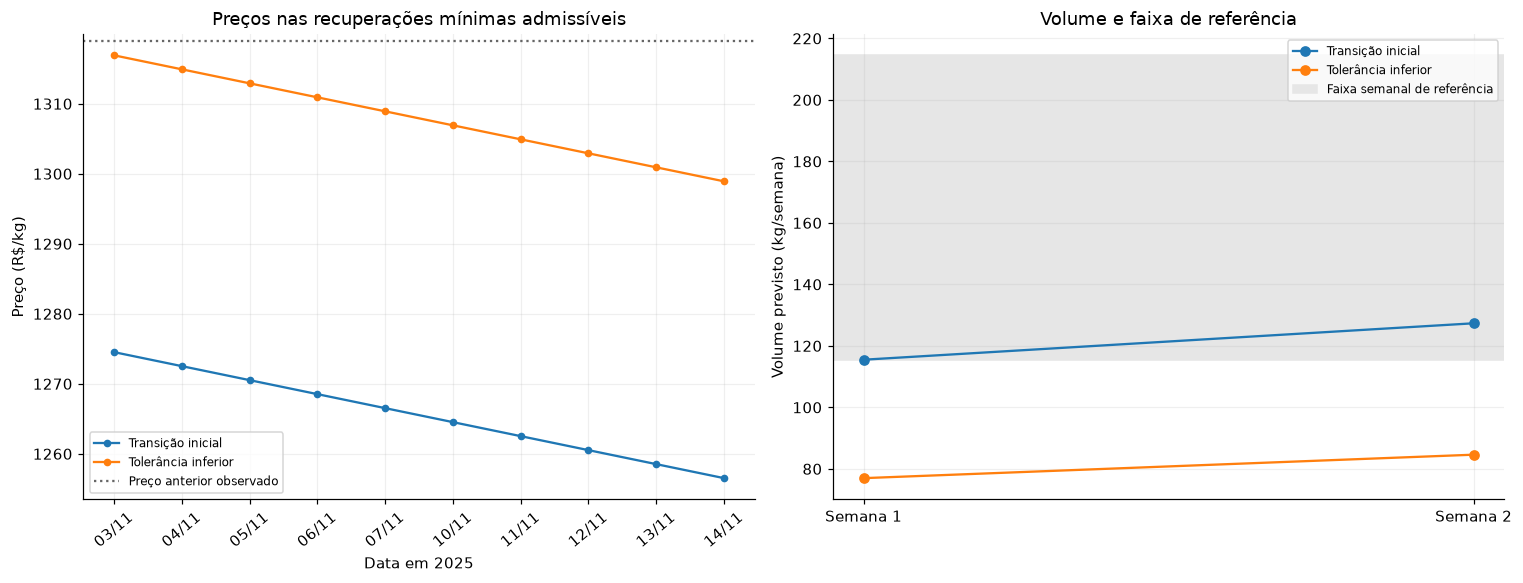

**Figura 3.1.5.** Trajetórias nas recuperações mínimas admissíveis, sem extrapolação do suporte. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Tabela 3.1.6.** Planos nas recuperações mínimas admissíveis. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,regra,margem_prevista_rs,semana_1_volume_previsto_kg,semana_2_volume_previsto_kg,gap
0,Transição inicial,40520.3784,115.5006,127.3491,0.0
1,Tolerância inferior,33336.9354,76.9868,84.6162,0.0


**Interpretação.** Os planos atendem às condições modificadas e ao teto interno recebido. A política de piso reduzido aceita vendas abaixo da faixa de referência; a de transição inicial ampliada admite uma mudança maior antes do primeiro dia. As condições acompanham cada plano exportado e devem permanecer visíveis em seu uso.

In [7]:
policy_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for row in thresholds:
    if row['minimum'] is None:
        continue
    result = study.evaluate(study.relaxation_at(row['rule'], row['minimum']))
    label = LABELS[row['rule']]
    daily, weekly = result['daily'], result['weekly']
    axes[0].plot(range(problem.n_days), daily['preco_kg'], 'o-', ms=4, label=label)
    axes[1].plot([1, 2], weekly['volume_previsto_kg'], 'o-', label=label)
    policy_rows.append(dict(regra=label, **summarize(result)))
policy_table = pd.DataFrame(policy_rows)
policy_table.to_csv(TABLES / 'politicas_minimas.csv', index=False)
axes[0].axhline(problem.initial_price, color='0.4', ls=':', label='Preço anterior observado')
axes[0].set_xticks(range(problem.n_days), [f'{d:%d/%m}' for d in problem.dates], rotation=40)
axes[0].set(xlabel='Data em 2025', ylabel='Preço (R$/kg)', title='Preços nas recuperações mínimas admissíveis')
axes[1].axhspan(nominal_target*(1-problem.tol_lower), nominal_target*(1+problem.tol_upper),
               color='.9', label='Faixa semanal de referência')
axes[1].set_xticks([1, 2], ['Semana 1', 'Semana 2'])
axes[1].set(ylabel='Volume previsto (kg/semana)', title='Volume e faixa de referência')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'planos_minimos.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Trajetórias nas recuperações mínimas admissíveis, sem extrapolação do suporte')
exibir_tabela(policy_table[['regra', 'margem_prevista_rs', 'semana_1_volume_previsto_kg',
                       'semana_2_volume_previsto_kg', 'gap']].round(4), 'Planos nas recuperações mínimas admissíveis')
publicar('**Interpretação.** Os planos atendem às condições modificadas e ao teto interno recebido. '
         'A política de piso reduzido aceita vendas abaixo da faixa de referência; a de transição '
         'inicial ampliada admite uma mudança maior antes do primeiro dia. As condições acompanham cada plano '
         'exportado e devem permanecer visíveis em seu uso.')

## 8. Conjuntos parciais das quatro famílias de regras

**Pergunta.** Quais conjuntos de alterações de preço, piso e teto permitem aumentar a margem
prevista em relação às recuperações mínimas isoladas?

**Método.** A grade cruza simultaneamente o limite da primeira mudança, a variação interna,
a tolerância inferior e a tolerância superior. Inclui condições com nenhuma, uma, duas, três ou
quatro famílias alteradas. A meta nominal, o preço anterior observado, a curva, o custo, o imposto
e o suporte permanecem fixos. Todos os limites continuam finitos e exigidos em cada cenário.

O piso e o teto são calculados e verificados em cada semana. Nesta grade, a mesma tolerância
inferior é aplicada às duas semanas, e a mesma tolerância superior é aplicada às duas; os dois
lados são independentes. O volume de uma semana não compensa o descumprimento da outra.

As faixas amostradas são escolhas de análise, não limites comerciais aprovados. Manter um piso
menos exigente pode recuperar a viabilidade; admitir um teto maior pode permitir mais margem.
Os resultados não pressupõem que flexibilizar todas as famílias seja sempre necessário.

In [8]:
partial_grids = {
    'transicao_inicial_rs': sorted(set([problem.init_var, 10, 20, 30, 40, 50, 60])),
    'variacao_interna_rs': sorted(set([problem.daily_variation, 5, 10, 15, 20, 25, 30])),
    'tolerancia_inferior': sorted(set([problem.tol_lower, .40, .50, .55, .60])),
    'tolerancia_superior': sorted(set([problem.tol_upper, .35, .40])),
}
# As posições de referência vêm do artefato; os outros valores definem a resolução da análise.
for key, nominal in [('transicao_inicial_rs', problem.init_var),
                     ('variacao_interna_rs', problem.daily_variation),
                     ('tolerancia_inferior', problem.tol_lower),
                     ('tolerancia_superior', problem.tol_upper)]:
    partial_grids[key] = [value for value in partial_grids[key] if value >= nominal]
partial_grids['variacao_interna_rs'] = [value for value in partial_grids['variacao_interna_rs'] if value <= MAX_INTERNAL]
partial_rows = []
for initial, daily, lower, upper in product(*partial_grids.values()):
    relaxation = Relaxation(
        initial_transition_factor=initial/problem.init_var,
        daily_variation_factor=daily/problem.daily_variation,
        tolerance_lower_factor=lower/problem.tol_lower,
        tolerance_upper_factor=upper/problem.tol_upper,
    )
    partial_rows.append(summarize(study.evaluate(relaxation)))

def declarar_folgas(frame):
    frame = frame.drop_duplicates('case_id').copy()
    frame['ampliacao_inicial_rs'] = (frame['transicao_inicial_rs']-problem.init_var).clip(lower=0)
    frame['ampliacao_interna_rs'] = (frame['variacao_interna_rs']-problem.daily_variation).clip(lower=0)
    frame['reducao_piso_kg'] = nominal_target*(frame['tolerancia_inferior']-problem.tol_lower)
    frame['ampliacao_teto_kg'] = nominal_target*(frame['tolerancia_superior']-problem.tol_upper)
    for name, column in [('primeira_mudanca', 'ampliacao_inicial_rs'),
                         ('variacao_interna', 'ampliacao_interna_rs'),
                         ('piso', 'reducao_piso_kg'), ('teto', 'ampliacao_teto_kg')]:
        frame[f'flex_{name}'] = frame[column] > 1e-8
    frame['n_familias_flexibilizadas'] = frame[[
        'flex_primeira_mudanca', 'flex_variacao_interna', 'flex_piso', 'flex_teto'
    ]].sum(axis=1)
    return frame

partial_combinations = declarar_folgas(pd.DataFrame(partial_rows))
partial_combinations.to_csv(TABLES / 'combinacoes_quatro_regras.csv', index=False)
family_summary = partial_combinations.groupby('n_familias_flexibilizadas').agg(
    casos=('case_id', 'size'), planos_verificados=('plano_verificado', 'sum'),
    maior_margem_prevista_rs=('margem_prevista_rs', 'max'),
)
exibir_tabela(pd.DataFrame([
    {'Parâmetro': key, 'Valores examinados': ', '.join(numero(value, 2) for value in values)}
    for key, values in partial_grids.items()
]), 'Valores das quatro famílias de regras na grade conjunta')
exibir_tabela(family_summary.round(2), 'Resultados por quantidade de famílias flexibilizadas')
publicar(f"**Interpretação.** A grade contém **{len(partial_combinations)} combinações**, com "
         f"**{int(partial_combinations['plano_verificado'].sum())} planos verificados**. "
         "A quantidade de famílias alteradas descreve a configuração; não mede, sozinha, a "
         "intensidade da mudança. As diferenças de margem precisam ser lidas junto com os "
         "limites de preço e de volume de cada caso.")

**Tabela 3.1.7.** Valores das quatro famílias de regras na grade conjunta. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Parâmetro,Valores examinados
0,transicao_inicial_rs,"2,00, 10,00, 20,00, 30,00, 40,00, 50,00, 60,00"
1,variacao_interna_rs,"2,00, 5,00, 10,00, 15,00"
2,tolerancia_inferior,"0,30, 0,40, 0,50, 0,55, 0,60"
3,tolerancia_superior,"0,30, 0,35, 0,40"


**Tabela 3.1.8.** Resultados por quantidade de famílias flexibilizadas. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,casos,planos_verificados,maior_margem_prevista_rs
n_familias_flexibilizadas,,,
0,1,0,NaN
1,15,4,43127.56
2,80,48,47181.80
3,180,149,47502.68
4,144,138,47502.68


**Interpretação.** A grade contém **420 combinações**, com **339 planos verificados**. A quantidade de famílias alteradas descreve a configuração; não mede, sozinha, a intensidade da mudança. As diferenças de margem precisam ser lidas junto com os limites de preço e de volume de cada caso.

## 9. Alternativas eficientes com aumento de margem

**Pergunta.** Quais combinações parciais entregam margens maiores e quais alterações operacionais exigem?

**Método.** As combinações são comparadas junto com as recuperações mínimas isoladas. Uma alternativa
é dominada se outra exige ampliações não maiores na primeira mudança e na variação interna, redução
não maior do piso e ampliação não maior do teto, entregando margem equivalente ou superior. Pelo
menos uma dessas condições precisa ser estritamente melhor.

A comparação usa o limitante de margem do solver e equivalência monetária de **R$ 0,10** para
acomodar as tolerâncias numéricas. Somente planos verificados com ótimo certificado são comparados.
Cada caso descartado conserva a identificação de um caso que o domina. Essa fronteira financeira
considera a margem junto com as quatro folgas; a fronteira operacional dos mapas anteriores
considera somente as alterações necessárias para obter factibilidade.

A referência financeira é a maior margem entre as recuperações mínimas isoladas admissíveis. O caso com
todas as regras originais é inviável e não recebe margem de comparação. As diferenças apresentadas
são entre configurações matemáticas, não ganhos realizados sobre a operação histórica.

O quadro de destaques usa critérios explícitos: maior margem mantendo a faixa semanal original;
maior margem mantendo a primeira mudança original; posição central da grade da primeira mudança
e teto permitido de variação interna, com faixa semanal mantida; maior margem entre alternativas eficientes com as quatro famílias
alteradas; e maior margem da grade. Perfis que coincidem são reunidos no mesmo caso. Todos os
outros casos eficientes permanecem disponíveis na tabela completa.

As referências sem regras operacionais são recebidas do artefato de resultados do planejamento.
A referência totalmente livre também admite extrapolação; sua margem serve apenas como comparação
teórica. Nenhuma alternativa parcial deste estudo extrapola o suporte observado.

A referência financeira e todas as alternativas parciais respeitam o teto recebido para a variação
interna. As referências com regras removidas são apenas comparações teóricas e não integram o
conjunto de alternativas comerciais. A primeira mudança permanece identificada separadamente.

**Tabela 3.1.9.** Alternativas eficientes e comparação financeira. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Alternativa,Critério do destaque,Primeira mudança (R$/kg),Variação interna (R$/kg),Piso por semana (kg),Teto por semana (kg),Margem total prevista (R$),Diferença da referência (R$),Diferença da referência (%)
0,A1,Primeira mudança mantida,2.0,15.0,82.5,214.50,41802.32,1281.94,3.16
1,A2,Quatro famílias flexibilizadas,20.0,15.0,99.0,222.75,43995.32,3474.94,8.58
2,A3,Primeira mudança intermediária; variação no teto,30.0,15.0,115.5,214.50,44865.39,4345.01,10.72
3,A4,Faixa semanal mantida,60.0,15.0,115.5,214.50,47181.80,6661.43,16.44
4,A5,Maior margem da grade,60.0,15.0,115.5,231.00,47502.68,6982.30,17.23


**Tabela 3.1.10.** Volumes, faixas e folgas semanais por alternativa. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,alternativa,semana,volume_previsto_kg,limite_inferior_kg,limite_superior_kg,folga_inferior_kg,folga_superior_kg
0,A1,semana_1,96.022,82.5,214.50,13.522,118.478
1,A1,semana_2,194.684,82.5,214.50,112.184,19.816
2,A2,semana_1,114.266,99.0,222.75,15.266,108.484
3,A2,semana_2,215.695,99.0,222.75,116.695,7.055
4,A3,semana_1,125.995,115.5,214.50,10.495,88.505
5,A3,semana_2,214.500,115.5,214.50,99.000,0.000
6,A4,semana_1,168.358,115.5,214.50,52.858,46.142
7,A4,semana_2,214.500,115.5,214.50,99.000,0.000
8,A5,semana_1,168.358,115.5,231.00,52.858,62.642
9,A5,semana_2,230.656,115.5,231.00,115.156,0.344


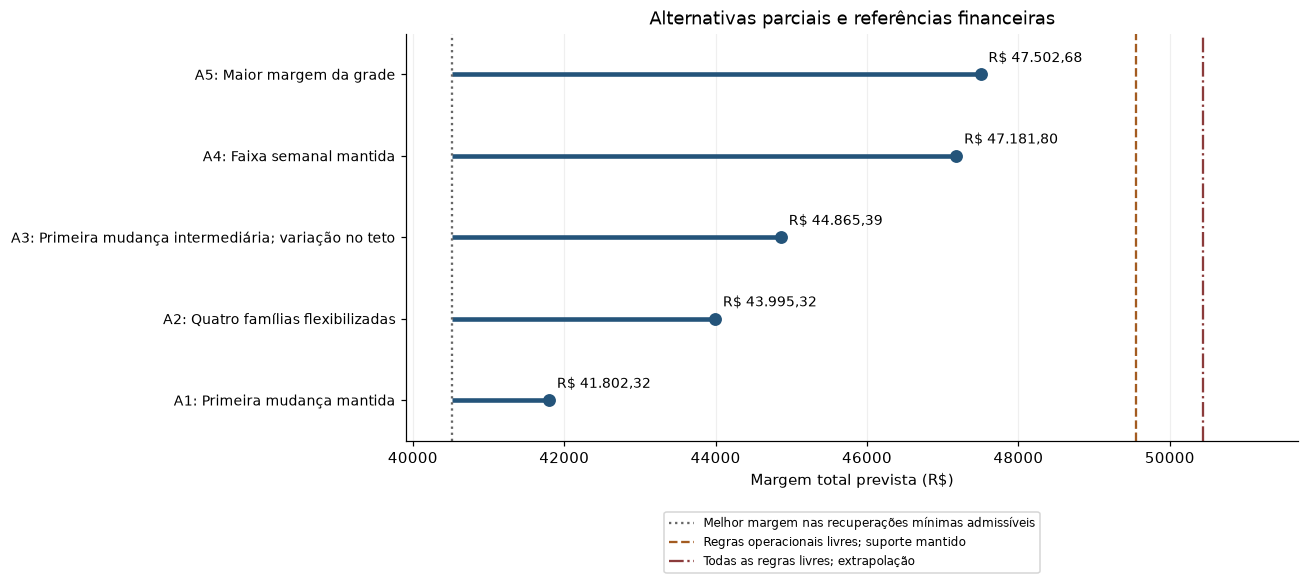

**Figura 3.1.6.** Margem prevista por alternativa e referências teóricas; diferenças não são ganhos realizados. Fonte: cálculo deste notebook; eixos indicam as unidades.

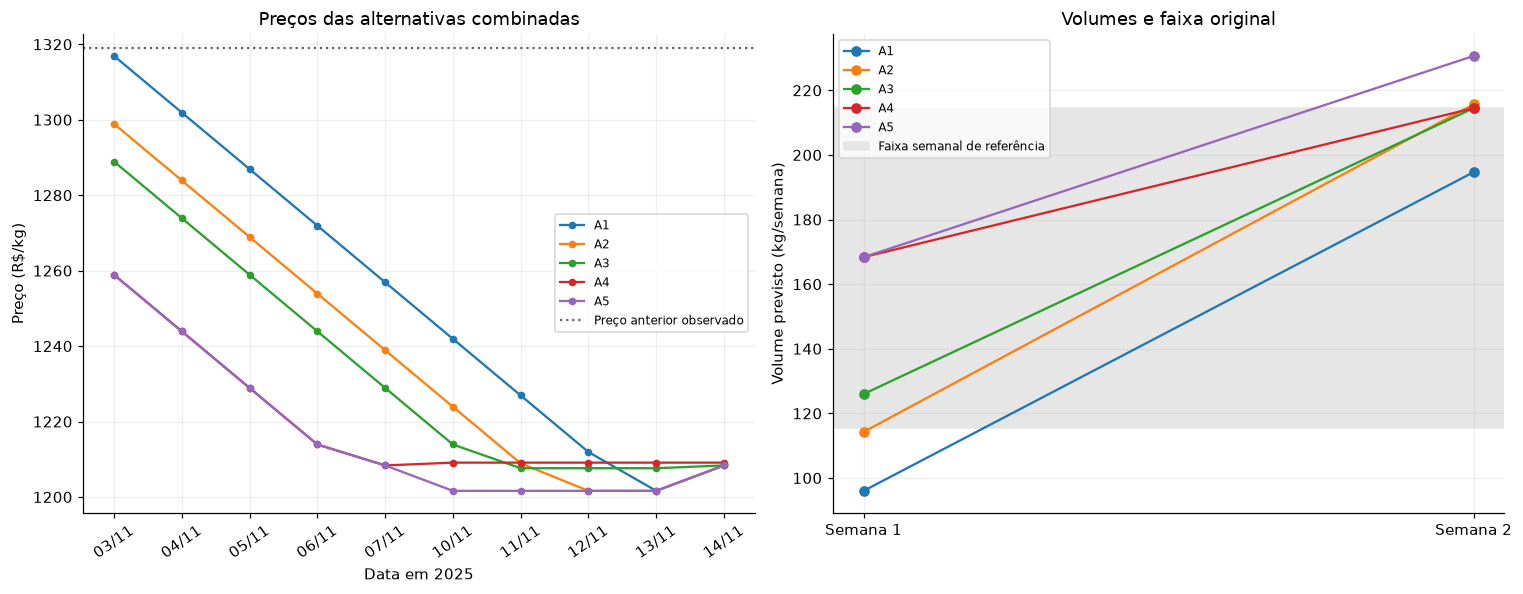

**Figura 3.1.7.** Preços e volumes diários das alternativas eficientes, com primeira mudança identificada separadamente. Fonte: cálculo deste notebook; eixos indicam as unidades.

**Referência de comparação.** A melhor margem entre as recuperações mínimas isoladas é **R$ 40.520,38**, pela alternativa **transição inicial**. As diferenças do quadro usam essa configuração factível, com curva, custo e imposto iguais. Não representam ganho histórico ou efeito causal.

**Resposta da grade.** Foram identificados **41 casos eficientes** na comparação entre folgas e margem. Os destaques mostram alternativas parciais que superam essa referência. Reduzir o piso e ampliar o teto são alterações separadas e estão explícitas no quadro e nas verificações de cada semana.

**A1: Primeira mudança mantida.** Primeira mudança de até R$ 2,00/kg, variação interna de até R$ 15,00/kg e faixa de 82,50 a 214,50 kg por semana. Margem prevista de **R$ 41.802,32**, diferença de **R$ 1.281,94 (3,16%)** sobre a referência factível.

**A2: Quatro famílias flexibilizadas.** Primeira mudança de até R$ 20,00/kg, variação interna de até R$ 15,00/kg e faixa de 99,00 a 222,75 kg por semana. Margem prevista de **R$ 43.995,32**, diferença de **R$ 3.474,94 (8,58%)** sobre a referência factível.

**A3: Primeira mudança intermediária; variação no teto.** Primeira mudança de até R$ 30,00/kg, variação interna de até R$ 15,00/kg e faixa de 115,50 a 214,50 kg por semana. Margem prevista de **R$ 44.865,39**, diferença de **R$ 4.345,01 (10,72%)** sobre a referência factível.

**A4: Faixa semanal mantida.** Primeira mudança de até R$ 60,00/kg, variação interna de até R$ 15,00/kg e faixa de 115,50 a 214,50 kg por semana. Margem prevista de **R$ 47.181,80**, diferença de **R$ 6.661,43 (16,44%)** sobre a referência factível.

**A5: Maior margem da grade.** Primeira mudança de até R$ 60,00/kg, variação interna de até R$ 15,00/kg e faixa de 115,50 a 231,00 kg por semana. Margem prevista de **R$ 47.502,68**, diferença de **R$ 6.982,30 (17,23%)** sobre a referência factível.

**Comparação teórica.** A referência com todas as regras livres, incluindo extrapolação, prevê R$ 50.432,89. A maior margem parcial da grade corresponde a 94,19% desse valor. Ela é ótima para as condições daquele caso, mas a grade não demonstra a melhor combinação contínua nem estabelece quais limites comerciais a operação deve aceitar.

**Papel do piso.** A maior margem desta grade preserva o piso semanal original. Reduzir o mínimo continua sendo uma alternativa para recuperar viabilidade com outros limites de preço, mas não é necessário para atingir esse resultado financeiro.

**Efeito isolado do teto nessa combinação.** Com os mesmos limites de preço e o mesmo piso, ampliar o teto de 214,50 para 231,00 kg eleva a margem prevista em **R$ 320,88**. Isso distingue o efeito de admitir mais volume do efeito de ampliar as mudanças de preço.

In [9]:
FINANCIAL_EQUIVALENCE_RS = .10
cost_columns = ['ampliacao_inicial_rs', 'ampliacao_interna_rs',
                'reducao_piso_kg', 'ampliacao_teto_kg']
comparison_pool = declarar_folgas(pd.concat([
    partial_combinations, policy_table.drop(columns='regra')
], ignore_index=True))
financial_comparison = compare_margin_relaxations(
    comparison_pool, cost_columns, margin_tolerance=FINANCIAL_EQUIVALENCE_RS)
efficient = financial_comparison.loc[
    financial_comparison['dominancia_financeira'].eq('eficiente')].copy()
financial_comparison.to_csv(TABLES / 'dominancia_financeira.csv', index=False)
efficient.to_csv(TABLES / 'alternativas_eficientes.csv', index=False)

baseline_recovery = policy_table.loc[policy_table['margem_prevista_rs'].idxmax()]
reference_margin = float(baseline_recovery['margem_prevista_rs'])
growth = efficient.loc[efficient['margem_prevista_rs'] > reference_margin+FINANCIAL_EQUIVALENCE_RS].copy()
assert not growth.empty, 'A grade não encontrou combinações eficientes que superem a referência.'
selected_profiles = {}

def destacar(label, panel):
    if panel.empty:
        return
    ordered = panel.sort_values(['margem_prevista_rs', *cost_columns],
                                ascending=[False, True, True, True, True])
    row = ordered.iloc[0].to_dict()
    entry = selected_profiles.setdefault(row['case_id'], dict(row, destaques=[]))
    entry['destaques'].append(label)

destacar('Faixa semanal mantida', growth.loc[~growth['flex_piso'] & ~growth['flex_teto']])
destacar('Primeira mudança mantida', growth.loc[~growth['flex_primeira_mudanca']])
initial_mid = partial_grids['transicao_inicial_rs'][len(partial_grids['transicao_inicial_rs'])//2]
daily_mid = max(partial_grids['variacao_interna_rs'])
destacar('Primeira mudança intermediária; variação no teto', growth.loc[
    np.isclose(growth['transicao_inicial_rs'], initial_mid)
    & np.isclose(growth['variacao_interna_rs'], daily_mid)
    & ~growth['flex_piso'] & ~growth['flex_teto']])
destacar('Quatro famílias flexibilizadas', growth.loc[growth['n_familias_flexibilizadas'].eq(4)])
destacar('Maior margem da grade', growth)
alternatives = pd.DataFrame(selected_profiles.values()).sort_values('margem_prevista_rs').reset_index(drop=True)
alternatives['alternativa'] = [f'A{index+1}' for index in range(len(alternatives))]
alternatives['destaques'] = alternatives['destaques'].map('; '.join)
alternatives['diferenca_referencia_factivel_rs'] = alternatives['margem_prevista_rs']-reference_margin
alternatives['diferenca_referencia_factivel_pct'] = 100*alternatives['diferenca_referencia_factivel_rs']/reference_margin

REFERENCE_PATH = ROOT / 'data/processed/minerva_otimizacao_resultado.json'
reference_file_hash = file_sha256(REFERENCE_PATH)
reference_artifact = load_artifact(REFERENCE_PATH)
assert reference_artifact['planning_inputs_sha256'] == planning_inputs['inputs_sha256'], 'Gere novamente os resultados do planejamento para as entradas atuais.'
assert reference_artifact['model_core_sha256'] == problem.artifact['model_core_sha256'], 'A referência financeira deve usar a mesma curva das entradas.'

def referencia_livre(extrapolate):
    matches = [result for result in reference_artifact['scenarios'].values()
               if not result['scenario']['enforce_daily_variation']
               and not result['scenario']['enforce_initial_anchor']
               and not result['scenario']['enforce_weekly_targets']
               and result['scenario']['extrapolate'] == extrapolate]
    assert len(matches) == 1
    result = matches[0]
    assert result['status'] == 'optimal' and result['validation']['satisfied']
    return {name: result[name] for name in ['status', 'total_margin_rs', 'bound_rs', 'gap',
                                           'model_core_sha256', 'scenario', 'extrapolation_bounds']}

benchmarks = {
    'artifact_file': str(REFERENCE_PATH.relative_to(ROOT)),
    'artifact_file_sha256': reference_file_hash,
    'minimum_recovery_reference': {
        'case_id': baseline_recovery['case_id'], 'regra': baseline_recovery['regra'],
        'margem_prevista_rs': reference_margin,
    },
    'observed_support_free_policy': referencia_livre(False),
    'fully_relaxed': referencia_livre(True),
}
free_margin = benchmarks['fully_relaxed']['total_margin_rs']
alternatives['distancia_referencia_teorica_rs'] = free_margin-alternatives['margem_prevista_rs']
alternatives['percentual_margem_referencia_teorica'] = 100*alternatives['margem_prevista_rs']/free_margin
alternatives.to_csv(TABLES / 'alternativas.csv', index=False)

alternative_plans, alternative_weeks = [], []
by_id = {result['case_id']: result for result in study.results.values()}
for row in alternatives.itertuples():
    result = by_id[row.case_id]
    daily = result['daily'].assign(
        alternativa=row.alternativa, case_id=row.case_id,
        transicao_inicial_permitida_rs=row.transicao_inicial_rs,
        variacao_interna_permitida_rs=row.variacao_interna_rs)
    weekly = result['weekly'].copy()
    weekly['alternativa'], weekly['case_id'] = row.alternativa, row.case_id
    weekly['piso_referencia_kg'] = weekly['semana'].map(problem.targets)*(1-problem.tol_lower)
    weekly['teto_referencia_kg'] = weekly['semana'].map(problem.targets)*(1+problem.tol_upper)
    alternative_plans.append(daily)
    alternative_weeks.append(weekly)
alternative_plans = pd.concat(alternative_plans, ignore_index=True)
alternative_weeks = pd.concat(alternative_weeks, ignore_index=True)
alternative_plans.to_csv(TABLES / 'planos_alternativas.csv', index=False)
alternative_weeks.to_csv(TABLES / 'resumo_semanal_alternativas.csv', index=False)

view = alternatives[[
    'alternativa', 'destaques', 'transicao_inicial_rs', 'variacao_interna_rs',
    'semana_1_piso_kg', 'semana_1_teto_kg', 'margem_prevista_rs',
    'diferenca_referencia_factivel_rs', 'diferenca_referencia_factivel_pct'
]].rename(columns={
    'alternativa': 'Alternativa', 'destaques': 'Critério do destaque',
    'transicao_inicial_rs': 'Primeira mudança (R$/kg)',
    'variacao_interna_rs': 'Variação interna (R$/kg)',
    'semana_1_piso_kg': 'Piso por semana (kg)', 'semana_1_teto_kg': 'Teto por semana (kg)',
    'margem_prevista_rs': 'Margem total prevista (R$)',
    'diferenca_referencia_factivel_rs': 'Diferença da referência (R$)',
    'diferenca_referencia_factivel_pct': 'Diferença da referência (%)',
})
exibir_tabela(view.round(2), 'Alternativas eficientes e comparação financeira')
exibir_tabela(alternative_weeks[['alternativa', 'semana', 'volume_previsto_kg',
                           'limite_inferior_kg', 'limite_superior_kg',
                           'folga_inferior_kg', 'folga_superior_kg']].round(3), 'Volumes, faixas e folgas semanais por alternativa')

fig, ax = plt.subplots(figsize=(12, 5.5))
y = np.arange(len(alternatives))
ax.hlines(y, reference_margin, alternatives['margem_prevista_rs'], color='#24547a', lw=3)
ax.scatter(alternatives['margem_prevista_rs'], y, color='#24547a', s=55, zorder=3)
for position, row in enumerate(alternatives.itertuples()):
    ax.annotate(f'R$ {numero(row.margem_prevista_rs)}', (row.margem_prevista_rs, position),
                xytext=(5, 8), textcoords='offset points', fontsize=9)
ax.set_yticks(y, [f'{r.alternativa}: {r.destaques}' for r in alternatives.itertuples()], fontsize=9)
ax.axvline(reference_margin, color='0.4', ls=':', label='Melhor margem nas recuperações mínimas admissíveis')
ax.axvline(benchmarks['observed_support_free_policy']['total_margin_rs'], color='#a35b20',
           ls='--', label='Regras operacionais livres; suporte mantido')
ax.axvline(free_margin, color='#8b3b3b', ls='-.', label='Todas as regras livres; extrapolação')
ax.set(xlabel='Margem total prevista (R$)', title='Alternativas parciais e referências financeiras')
ax.set_xlim(reference_margin*.985, free_margin*1.025)
ax.set_ylim(-.5, len(alternatives)-.5)
ax.grid(axis='x', alpha=.2)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.16), fontsize=8, ncol=1)
fig.tight_layout()
fig.savefig(FIGURES / 'alternativas_margem.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Margem prevista por alternativa e referências teóricas; diferenças não são ganhos realizados')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for row in alternatives.itertuples():
    daily = by_id[row.case_id]['daily']
    weekly = by_id[row.case_id]['weekly']
    axes[0].plot(range(problem.n_days), daily['preco_kg'], 'o-', ms=4, label=row.alternativa)
    axes[1].plot([1, 2], weekly['volume_previsto_kg'], 'o-', label=row.alternativa)
axes[0].axhline(problem.initial_price, color='0.4', ls=':', label='Preço anterior observado')
axes[0].set_xticks(range(problem.n_days), [f'{date:%d/%m}' for date in problem.dates], rotation=35)
axes[0].set(xlabel='Data em 2025', ylabel='Preço (R$/kg)', title='Preços das alternativas combinadas')
axes[1].axhspan(nominal_target*(1-problem.tol_lower), nominal_target*(1+problem.tol_upper),
               color='.9', label='Faixa semanal de referência')
axes[1].set_xticks([1, 2], ['Semana 1', 'Semana 2'])
axes[1].set(ylabel='Volume previsto (kg/semana)', title='Volumes e faixa original')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'alternativas_planos.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Preços e volumes diários das alternativas eficientes, com primeira mudança identificada separadamente')

best = alternatives.loc[alternatives['margem_prevista_rs'].idxmax()]
publicar(f"**Referência de comparação.** A melhor margem entre as recuperações mínimas isoladas "
         f"é **R$ {numero(reference_margin)}**, pela alternativa **{baseline_recovery['regra'].lower()}**. "
         "As diferenças do quadro usam essa configuração factível, com curva, custo e imposto iguais. "
         "Não representam ganho histórico ou efeito causal.\n\n"
         f"**Resposta da grade.** Foram identificados **{len(efficient)} casos eficientes** na "
         "comparação entre folgas e margem. Os destaques mostram alternativas parciais que "
         "superam essa referência. Reduzir o piso e ampliar o teto são alterações separadas e "
         "estão explícitas no quadro e nas verificações de cada semana.")
for row in alternatives.itertuples():
    publicar(f"**{row.alternativa}: {row.destaques}.** Primeira mudança de até "
             f"R$ {numero(row.transicao_inicial_rs)}/kg, variação interna de até "
             f"R$ {numero(row.variacao_interna_rs)}/kg e faixa de "
             f"{numero(row.semana_1_piso_kg)} a {numero(row.semana_1_teto_kg)} kg por semana. "
             f"Margem prevista de **R$ {numero(row.margem_prevista_rs)}**, diferença de "
             f"**R$ {numero(row.diferenca_referencia_factivel_rs)} "
             f"({numero(row.diferenca_referencia_factivel_pct)}%)** sobre a referência factível.")
publicar(f"**Comparação teórica.** A referência com todas as regras livres, incluindo extrapolação, "
         f"prevê R$ {numero(free_margin)}. A maior margem parcial da grade corresponde a "
         f"{numero(best['percentual_margem_referencia_teorica'])}% desse valor. Ela é ótima para "
         "as condições daquele caso, mas a grade não demonstra a melhor combinação contínua "
         "nem estabelece quais limites comerciais a operação deve aceitar.")
if not best['flex_piso']:
    publicar('**Papel do piso.** A maior margem desta grade preserva o piso semanal original. '
             'Reduzir o mínimo continua sendo uma alternativa para recuperar viabilidade com '
             'outros limites de preço, mas não é necessário para atingir esse resultado financeiro.')
if best['flex_teto']:
    same_prices = partial_combinations.loc[
        np.isclose(partial_combinations['transicao_inicial_rs'], best['transicao_inicial_rs'])
        & np.isclose(partial_combinations['variacao_interna_rs'], best['variacao_interna_rs'])
        & np.isclose(partial_combinations['tolerancia_inferior'], best['tolerancia_inferior'])
        & np.isclose(partial_combinations['tolerancia_superior'], problem.tol_upper)
        & partial_combinations['plano_verificado']
    ]
    if not same_prices.empty:
        before = same_prices.iloc[0]
        upper_increment = best['margem_prevista_rs']-before['margem_prevista_rs']
        publicar(f"**Efeito isolado do teto nessa combinação.** Com os mesmos limites de preço e "
                 f"o mesmo piso, ampliar o teto de {numero(before['semana_1_teto_kg'])} para "
                 f"{numero(best['semana_1_teto_kg'])} kg eleva a margem prevista em "
                 f"**R$ {numero(upper_increment)}**. Isso distingue o efeito de admitir mais volume "
                 "do efeito de ampliar as mudanças de preço.")


## 10. Verificação, artefatos e limites de uso

**Pergunta.** Como reproduzir as análises e identificar exatamente as condições de cada plano?

**Método.** As tabelas preservam casos inviáveis e os status de término. Cada plano é recalculado
pela inferência canônica, incluindo smearing, imposto e custo. As regras ativas são verificadas
independentemente. Nas curvas de flexibilização, os limitantes do solver são usados para conferir
se os resultados são compatíveis com a ampliação do conjunto admissível.

O arquivo consolidado registra os hashes das entradas e da curva, as grades, os mínimos com seus
intervalos e todos os casos resolvidos. Os planos diários têm identificador para cruzamento com
a tabela de condições. O estudo não utiliza os dados reais do horizonte para escolher folgas.

In [10]:
cases = study.table()
assert cases['variacao_interna_rs'].le(MAX_INTERNAL+1e-9).all()
assert set(cases['status']) <= {'optimal', 'infeasible'}, 'Há casos sem certificado para revisar.'
assert cases.loc[cases['margem_prevista_rs'].notna(), 'plano_verificado'].all()
for _, panel in curves.groupby('regra'):
    valid = panel.loc[panel['plano_verificado']].sort_values('valor')
    if len(valid) > 1:
        for small, large in zip(valid.iloc[:-1].itertuples(), valid.iloc[1:].itertuples()):
            assert small.margem_prevista_rs <= large.limite_superior_margem_rs + .02
plans = pd.concat([
    result['daily'].assign(case_id=result['case_id'])
    for result in study.results.values() if result['daily'] is not None
], ignore_index=True)
assert not plans['extrapolado'].any()
assert plans['custo_kg'].eq(problem.costs[0]).all()
cases.to_csv(TABLES / 'casos.csv', index=False)
plans.to_csv(PLAN_PATH, index=False)

def serializar(value):
    if isinstance(value, pd.DataFrame):
        return serializar(value.to_dict(orient='records'))
    if isinstance(value, dict):
        return {str(key): serializar(v) for key, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [serializar(v) for v in value]
    if isinstance(value, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(value).isoformat()
    if isinstance(value, np.generic):
        return serializar(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

payload = {
    'artifact_version': 1,
    'planning_inputs_file': str(INPUT_PATH.relative_to(ROOT)),
    'planning_inputs_sha256': planning_inputs['inputs_sha256'],
    'model_file': planning_inputs['model_file'],
    'model_core_sha256': problem.artifact['model_core_sha256'],
    'model_file_sha256': model_hash,
    'decision_cutoff': planning_inputs['decision_cutoff'],
    'unit_cost_kg': float(problem.costs[0]),
    'initial_price_observed': float(problem.initial_price),
    'tax_rate': float(problem.tax_rate),
    'smearing_factor': problem.artifact['smearing_factor'],
    'holdout_used': False,
    'thresholds': thresholds,
    'curve_grids': grids,
    'relaxation_limits_file': str(LIMITS_PATH.relative_to(ROOT)),
    'relaxation_limits_file_sha256': limits_file_hash,
    'relaxation_limits': relaxation_limits,
    'combinations': combination_table.to_dict(orient='records'),
    'frontiers': frontiers.to_dict(orient='records'),
    'partial_grids': partial_grids,
    'partial_combinations': partial_combinations.to_dict(orient='records'),
    'financial_equivalence_rs': FINANCIAL_EQUIVALENCE_RS,
    'financial_comparison': financial_comparison.to_dict(orient='records'),
    'alternatives': alternatives.to_dict(orient='records'),
    'benchmarks': benchmarks,
    'cases': {result['case_id']: result for result in study.results.values()},
}
RESULT_PATH.write_text(json.dumps(serializar(payload), ensure_ascii=False, indent=2, allow_nan=False)+'\n')
assert file_sha256(LIMITS_PATH) == limits_file_hash
assert file_sha256(INPUT_PATH) == input_hash
assert file_sha256(MODEL_PATH) == model_hash
assert file_sha256(REFERENCE_PATH) == reference_file_hash
publicar(f"**Verificação concluída.** {len(cases)} casos distintos, "
         f"{int(cases['plano_verificado'].sum())} planos verificados e "
         f"{int(cases['status'].eq('infeasible').sum())} casos inviáveis provados. "
         "As entradas e a curva permaneceram idênticas durante o estudo.")

**Verificação concluída.** 508 casos distintos, 380 planos verificados e 128 casos inviáveis provados. As entradas e a curva permaneceram idênticas durante o estudo.

## 11. Entregas e interpretação operacional

| Artefato | Conteúdo |
|---|---|
| `models/otimizacao/limites_flexibilizacoes.json` | Teto comercial da variação interna e tratamento separado da primeira mudança |
| `models/otimizacao/entradas_planejamento.json` | Entradas recebidas, calendário e referências às fontes |
| `reports/tables/relaxacoes/limiares_viabilidade.csv` | Intervalos entre inviabilidade provada e planos factíveis |
| `reports/tables/relaxacoes/curvas.csv`, `curva_teto.csv` | Efeito gradual de cada regra e condição |
| `reports/tables/relaxacoes/sensibilidade_meta_nominal.csv` | Metas com tolerâncias e regras de preço fixas |
| `reports/tables/relaxacoes/combinacoes.csv`, `fronteiras.csv` | Grades e fronteiras operacionais amostradas |
| `reports/tables/relaxacoes/casos.csv`, `politicas_minimas.csv` | Condições, certificados, margens e folgas |
| `reports/tables/relaxacoes/combinacoes_quatro_regras.csv` | Grade conjunta de preço, piso e teto |
| `reports/tables/relaxacoes/dominancia_financeira.csv`, `alternativas_eficientes.csv` | Comparação de quatro folgas e margem, com casos dominantes identificados |
| `reports/tables/relaxacoes/alternativas.csv` | Destaques e diferenças frente à recuperação mínima de maior margem |
| `reports/tables/relaxacoes/planos_alternativas.csv`, `resumo_semanal_alternativas.csv` | Preços, volumes, faixas admitidas e folgas por alternativa |
| `data/processed/minerva_planos_relaxacoes.csv` | Planos diários identificados pelas condições |
| `data/processed/minerva_simulacao_relaxacoes.json` | Resultado consolidado e rastreabilidade |
| `reports/figures/relaxacoes/` | Curvas, mapas e trajetórias nos mínimos |

O preço anterior, o custo, o imposto e a curva vêm dos artefatos. As faixas das análises são
escolhas computacionais explícitas. Os mínimos e as margens são resultados matemáticos condicionais
à curva e às premissas. Os limites comerciais aceitáveis para flexibilizar regras precisam ser
fornecidos pela operação; não são inferidos dos dados de venda.

O menor afrouxamento resolve a viabilidade. Uma folga adicional pode aumentar a margem prevista,
mas demanda uma mudança operacional maior. A maior margem entre alternativas com regras diferentes
não representa ganho realizado nem determina automaticamente a recomendação comercial.

**Referência do problema.** Desafio de otimização de precificação aplicado ao segmento de carnes
in natura, `docs/referencias/Minerva_Unifesp_ITA.pdf`, e restrições da instância recebida.

## Referências metodológicas

- MINERVA FOODS; UNIFESP; ITA. *Otimização de precificação aplicado ao segmento de carnes in natura: Desafio Minerva-Unifesp-ITA*. 17 ago. 2026. [Enunciado](../docs/referencias/Minerva_Unifesp_ITA.pdf).
- PHILLIPS, Robert L. *Pricing and Revenue Optimization*. 2. ed. Stanford: Stanford University Press, 2021. cap. 4, seções 4.2 a 4.4. [Dados bibliográficos e fontes](../docs/referencias-bibliograficas.md).
- DUAN, Naihua. Smearing Estimate: A Nonparametric Retransformation Method. *Journal of the American Statistical Association*, 78(383), 605–610, 1983. [DOI](https://doi.org/10.1080/01621459.1983.10478017).
- MACKINNON, James G.; WHITE, Halbert. Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics*, 29(3), 305–325, 1985. [DOI](https://doi.org/10.1016/0304-4076(85)90158-7).
- HYNDMAN, Rob J.; ATHANASOPOULOS, George. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021. cap. 5, seções 5.2 e 5.10. [Texto](https://otexts.com/fpp3/toolbox.html).
- GUROBI OPTIMIZATION, LLC. *Gurobi Optimizer Reference Manual*, versão 13.0. Seção Nonlinear Constraints. [Documentação](https://docs.gurobi.com/projects/optimizer/en/current/features/nonlinear.html).

O enunciado e a planilha são as fontes das regras. As tabelas exportadas por este notebook são as fontes dos resultados próprios. Cenários escolhidos pelo grupo são premissas de análise, sem respaldo atribuído a uma fonte externa. A revisão comparativa de Mullapudi, citada pelo enunciado, não é usada como fonte dos métodos estatísticos ou do solver e não integra esta bibliografia.